In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import json
from scipy import stats

C1 = "#2a78d6"  # blau
C2 = "#1baf7a"  # grün
C3 = "#eda100"  # gelb
C4 = "#e34948"  # rot
C5 = "#4a3aa7"  # violett
MUTED = "#898781"
GRID  = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor":   "#fcfcfb",
    "axes.edgecolor":   "#c3c2b7",
    "axes.linewidth":   0.8,
    "grid.color":       GRID,
    "grid.linewidth":   0.6,
    "xtick.color":      MUTED,
    "ytick.color":      MUTED,
    "text.color":       "#0b0b0b",
    "font.size":        11,
})

In [2]:
baseline = pd.read_csv("../results/nas_baseline.csv")
proxies = pd.read_csv("../results/nas_proxies.csv")
proxy_val = pd.read_csv("../results/proxy_validation.csv")
f1 = pd.read_csv("../results/f1_scaling.csv")

with open("../results/retrain_analysis_summary.json") as f:
    retrain = pd.DataFrame(json.load(f))

with open("../results/spt_ablation_summary.json") as f:
    spt_raw = json.load(f)
    
print(f"nas_baseline:     {len(baseline)} Architekturen")
print(f"nas_proxies:      {len(proxies)} Architekturen")
print(f"proxy_validation: {len(proxy_val)} Architekturen")
print(f"f1_scaling:       {len(f1)} Einträge")


nas_baseline:     120 Architekturen
nas_proxies:      56 Architekturen
proxy_validation: 100 Architekturen
f1_scaling:       24 Einträge


In [4]:
def pareto_front(df, acc_col="val_acc", param_col="params"):
    """Gibt Boolean-Maske zurück: True = Pareto-optimal."""
    n = len(df)
    is_pareto = np.ones(n, dtype=bool)
    acc = df[acc_col].values
    par = df[param_col].values
    for i in range(n):
        for j in range(n):
            if i == j: continue
            if acc[j] >= acc[i] and par[j] <= par[i] and (acc[j] > acc[i] or par[j] < par[i]):
                is_pareto[i] = False
                break
    return is_pareto


## Pareto-Front NAS Baseline

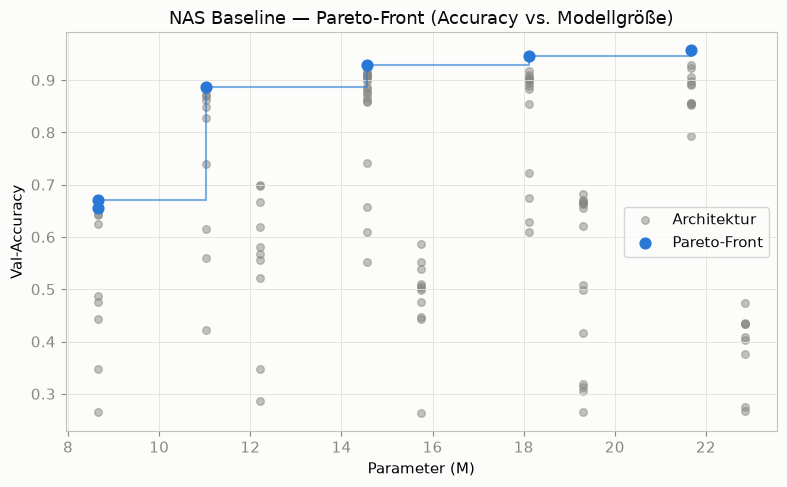

In [6]:
mask = pareto_front(baseline)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline.loc[~mask, "params"] / 1e6,
           baseline.loc[~mask, "val_acc"],
           color=MUTED, alpha=0.5, s=30, label="Architektur")
ax.scatter(baseline.loc[mask, "params"] / 1e6,
           baseline.loc[mask, "val_acc"],
           color=C1, s=60, zorder=5, label="Pareto-Front")

pf = baseline[mask].sort_values("params")
ax.step(pf["params"] / 1e6, pf["val_acc"],
        where="post", color=C1, linewidth=1.5, alpha=0.6)

ax.set_xlabel("Parameter (M)")
ax.set_ylabel("Val-Accuracy")
ax.set_title("NAS Baseline — Pareto-Front (Accuracy vs. Modellgröße)")
ax.legend()
ax.grid(True, axis="both")
plt.tight_layout()
plt.savefig("../results/plots/pareto_baseline.png", dpi=150)
plt.show()

## Baseline vs. Proxies (beide Pareto-Fronten)

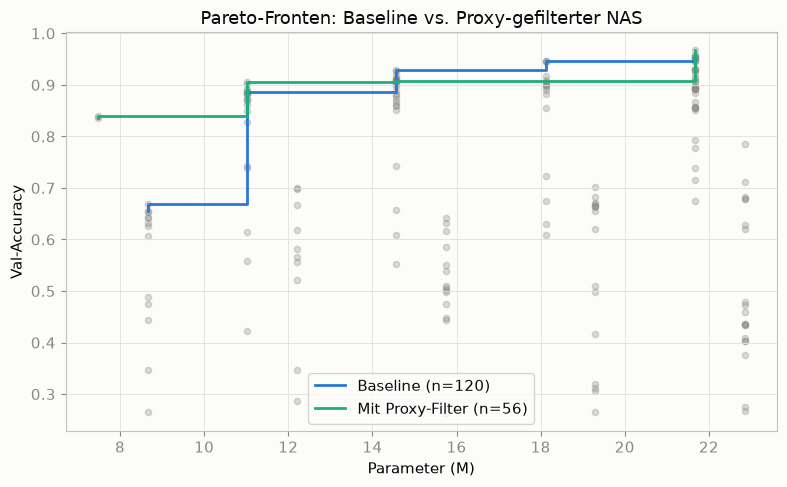

In [7]:
mask_b = pareto_front(baseline)
mask_p = pareto_front(proxies)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline["params"] / 1e6, baseline["val_acc"],
           color=MUTED, alpha=0.3, s=20)
ax.scatter(proxies["params"] / 1e6, proxies["val_acc"],
           color=MUTED, alpha=0.3, s=20)

pf_b = baseline[mask_b].sort_values("params")
pf_p = proxies[mask_p].sort_values("params")

ax.step(pf_b["params"] / 1e6, pf_b["val_acc"],
        where="post", color=C1, linewidth=2, label=f"Baseline (n=120)")
ax.step(pf_p["params"] / 1e6, pf_p["val_acc"],
        where="post", color=C2, linewidth=2, label=f"Mit Proxy-Filter (n={len(proxies)})")

ax.set_xlabel("Parameter (M)"); ax.set_ylabel("Val-Accuracy")
ax.set_title("Pareto-Fronten: Baseline vs. Proxy-gefilterter NAS")
ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/pareto_vergleich.png", dpi=150)
plt.show()


## Proxy Validation Scatter (3 Subplots)

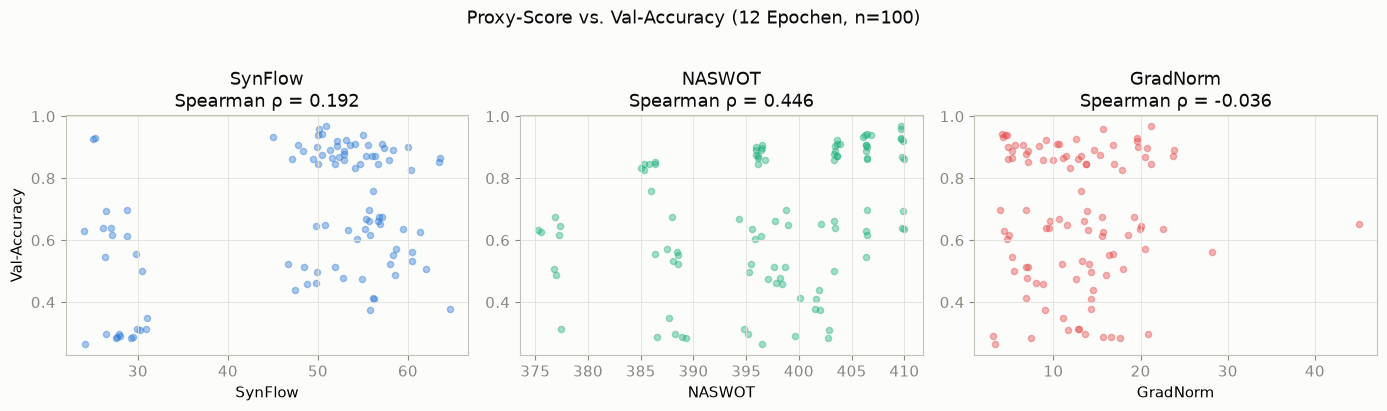

In [10]:
proxies_list = [
    ("synflow",  "SynFlow",  C1),
    ("naswot",   "NASWOT",   C2),
    ("gradnorm", "GradNorm", C4),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, label, color) in zip(axes, proxies_list):
    x = proxy_val[col]
    y = proxy_val["val_acc"]
    rho, pval = stats.spearmanr(x, y)
    ax.scatter(x, y, color=color, alpha=0.4, s=20)
    ax.set_xlabel(label)
    ax.set_ylabel("Val-Accuracy" if ax == axes[0] else "")
    ax.set_title(f"{label}\nSpearman ρ = {rho:.3f}")
    ax.grid(True)

plt.suptitle("Proxy-Score vs. Val-Accuracy (12 Epochen, n=100)", y=1.02)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


#### Synflow

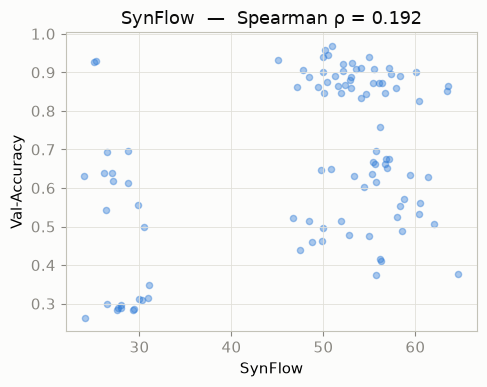

In [9]:
x = proxy_val["synflow"]
y = proxy_val["val_acc"]
rho, pval = stats.spearmanr(x, y)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color=C1, alpha=0.4, s=20)
ax.set_xlabel("SynFlow")
ax.set_ylabel("Val-Accuracy")
ax.set_title(f"SynFlow  —  Spearman ρ = {rho:.3f}")
ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter_synflow.png", dpi=150)
plt.show()

#### NASWOT

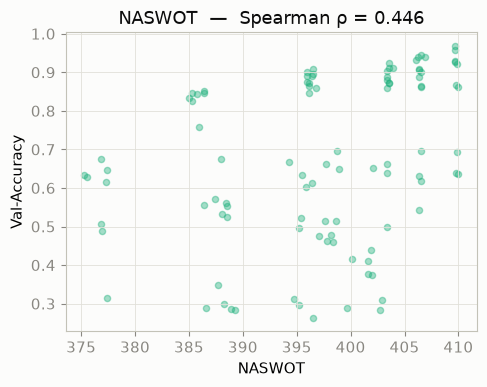

In [11]:
x = proxy_val["naswot"]
y = proxy_val["val_acc"]
rho, pval = stats.spearmanr(x, y)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color=C2, alpha=0.4, s=20)
ax.set_xlabel("NASWOT")
ax.set_ylabel("Val-Accuracy")
ax.set_title(f"NASWOT  —  Spearman ρ = {rho:.3f}")
ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter_naswot.png", dpi=150)
plt.show()

#### GradNorm

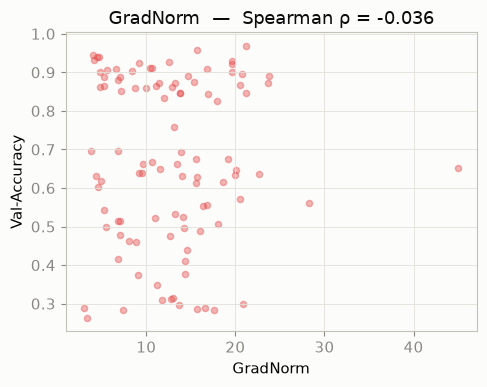

In [12]:
x = proxy_val["gradnorm"]
y = proxy_val["val_acc"]
rho, pval = stats.spearmanr(x, y)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, color=C4, alpha=0.4, s=20)
ax.set_xlabel("GradNorm")
ax.set_ylabel("Val-Accuracy")
ax.set_title(f"GradNorm  —  Spearman ρ = {rho:.3f}")
ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/proxy_scatter_gradnorm.png", dpi=150)
plt.show()


## F1 Datensatz-Skalierung

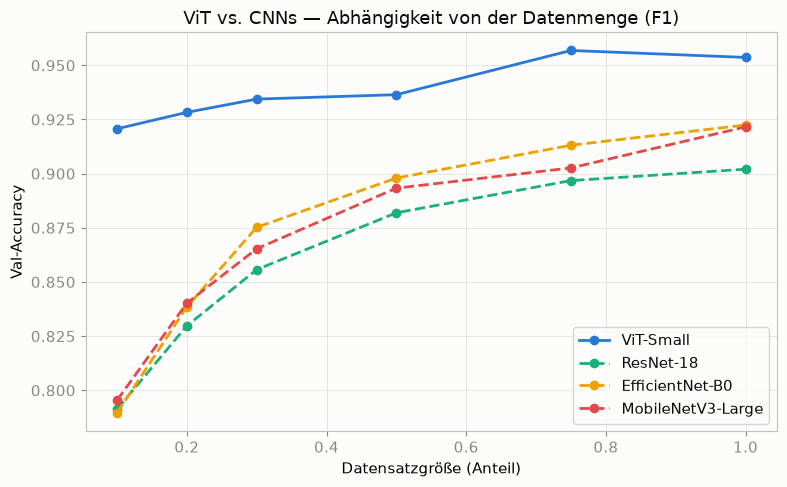

In [13]:
model_styles = {
    "vit_small":          (C1, "-",  "ViT-Small"),
    "resnet18":           (C2, "--", "ResNet-18"),
    "efficientnet_b0":    (C3, "--", "EfficientNet-B0"),
    "mobilenetv3_large":  (C4, "--", "MobileNetV3-Large"),
}

fig, ax = plt.subplots(figsize=(8, 5))
for model, (color, ls, label) in model_styles.items():
    d = f1[f1["model"] == model].sort_values("subsample_frac")
    ax.plot(d["subsample_frac"], d["best_val_acc"],
            color=color, linestyle=ls, linewidth=2,
            marker="o", markersize=6, label=label)

ax.set_xlabel("Datensatzgröße (Anteil)")
ax.set_ylabel("Val-Accuracy")
ax.set_title("ViT vs. CNNs — Abhängigkeit von der Datenmenge (F1)")
ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/f1_scaling.png", dpi=150)
plt.show()


## SPT-Ablation Lernkurven

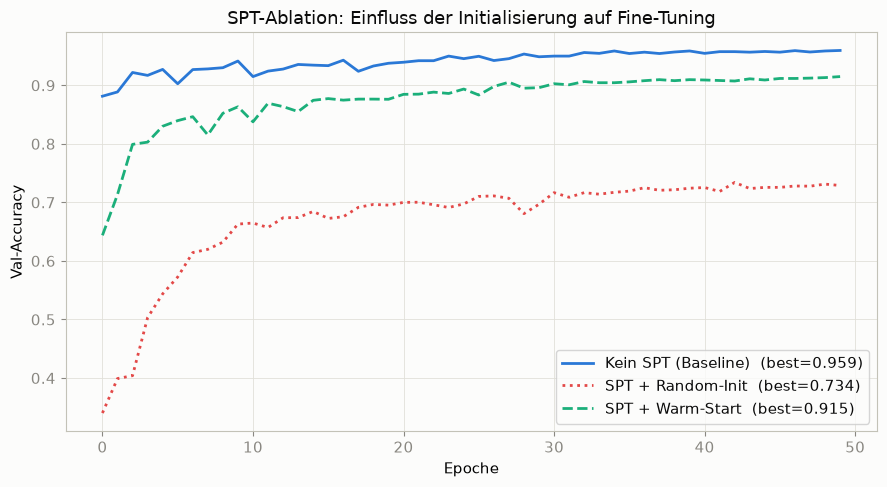

In [14]:
spt_styles = {
    "spt_none":   (C1, "-",  "Kein SPT (Baseline)"),
    "spt_warm":   (C2, "--", "SPT + Warm-Start"),
    "spt_random": (C4, ":",  "SPT + Random-Init"),
}

fig, ax = plt.subplots(figsize=(9, 5))
for entry in spt_raw:
    label_key = entry["label"]
    color, ls, label = spt_styles[label_key]
    epochs = [h["epoch"] for h in entry["history"]]
    vals   = [h["val_acc"] for h in entry["history"]]
    ax.plot(epochs, vals, color=color, linestyle=ls,
            linewidth=2, label=f"{label}  (best={entry['val_acc']:.3f})")

ax.set_xlabel("Epoche"); ax.set_ylabel("Val-Accuracy")
ax.set_title("SPT-Ablation: Einfluss der Initialisierung auf Fine-Tuning")
ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig("../results/plots/spt_ablation.png", dpi=150)
plt.show()

## Retrain-Analyse

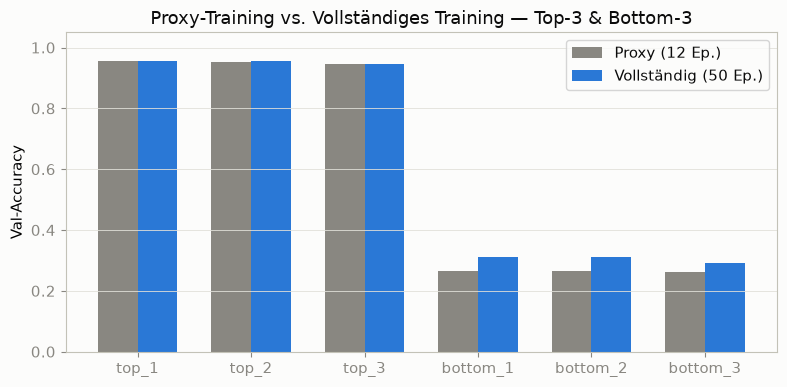

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(retrain))
w = 0.35

ax.bar(x - w/2, retrain["proxy_val_acc"], w, color=MUTED, label="Proxy (12 Ep.)")
ax.bar(x + w/2, retrain["full_val_acc"],  w, color=C1,    label="Vollständig (50 Ep.)")

ax.set_xticks(x)
ax.set_xticklabels(retrain["label"])
ax.set_ylabel("Val-Accuracy")
ax.set_title("Proxy-Training vs. Vollständiges Training — Top-3 & Bottom-3")
ax.legend(); ax.grid(True, axis="y")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("../results/plots/retrain_vergleich.png", dpi=150)
plt.show()


## Boxplots pro Parameter

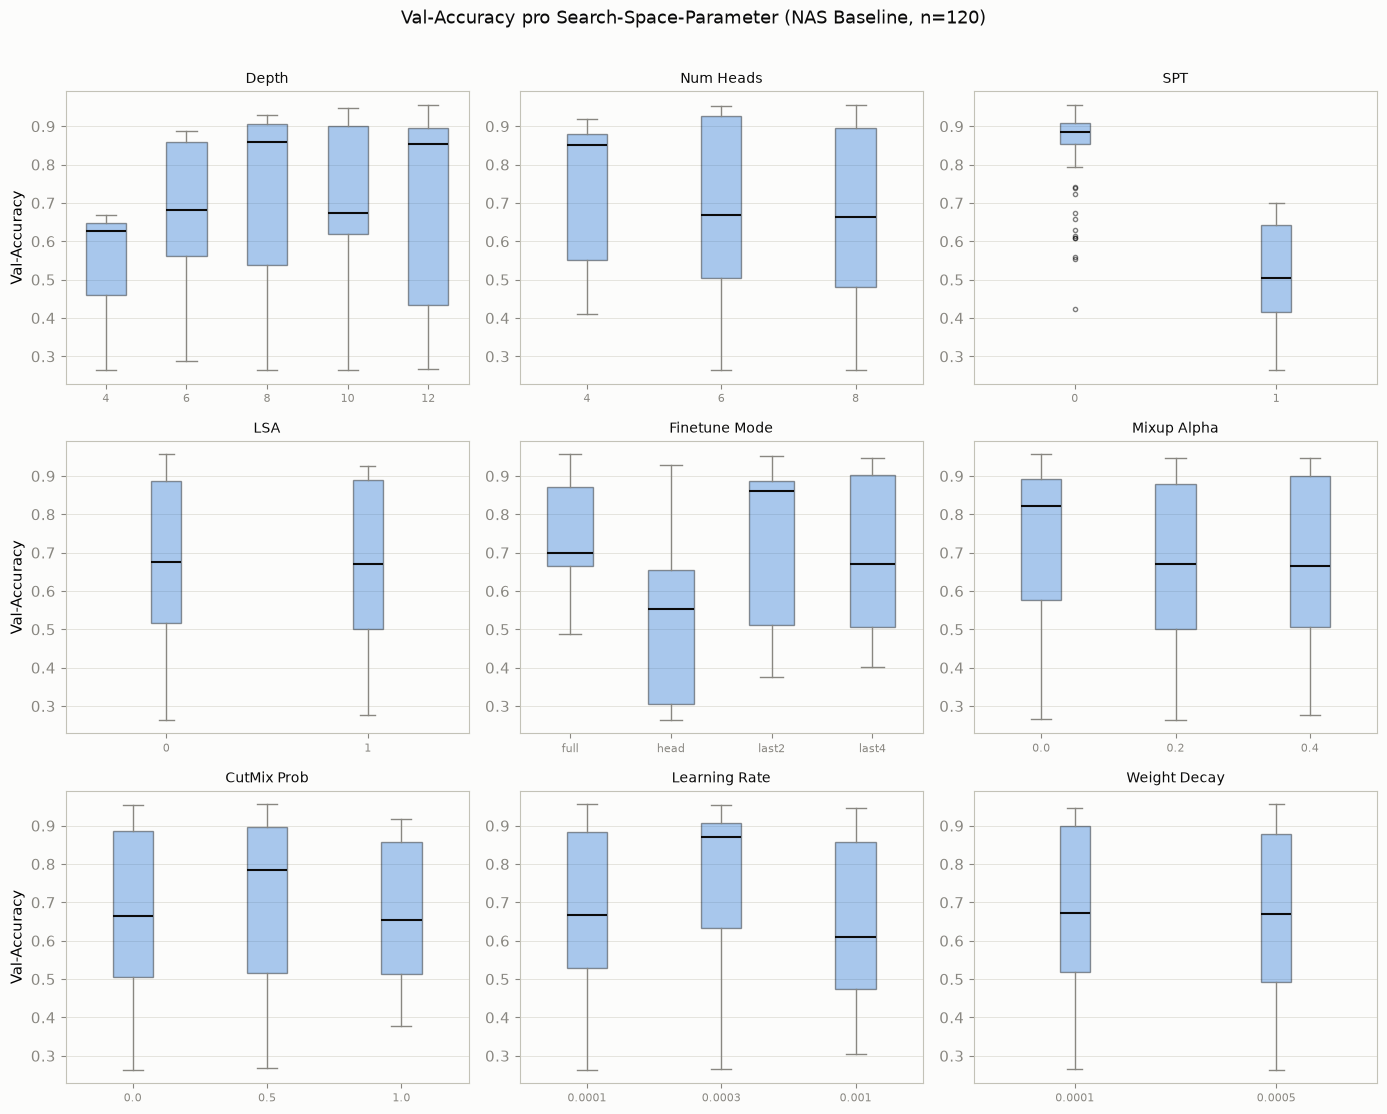

In [19]:
params = {
    "depth":        "Depth",
    "num_heads":    "Num Heads",
    "use_spt":      "SPT",
    "use_lsa":      "LSA",
    "finetune_mode":"Finetune Mode",
    "mixup_alpha":  "Mixup Alpha",
    "cutmix_prob":  "CutMix Prob",
    "lr":           "Learning Rate",
    "weight_decay": "Weight Decay",
}

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()

for ax, (col, label) in zip(axes, params.items()):
    groups = [baseline.loc[baseline[col] == v, "val_acc"].values
              for v in sorted(baseline[col].unique())]
    labels = [str(v) for v in sorted(baseline[col].unique())]

    bp = ax.boxplot(groups, tick_labels=labels, patch_artist=True,
                    medianprops=dict(color="#0b0b0b", linewidth=1.5),
                    boxprops=dict(facecolor=C1, alpha=0.4),
                    whiskerprops=dict(color=MUTED),
                    capprops=dict(color=MUTED),
                    flierprops=dict(marker="o", color=MUTED, markersize=3, alpha=0.5))

    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Val-Accuracy" if ax in axes[::3] else "")
    ax.grid(True, axis="y")
    ax.tick_params(axis="x", labelsize=8)

plt.suptitle("Val-Accuracy pro Search-Space-Parameter (NAS Baseline, n=120)", y=1.01)
plt.tight_layout()
plt.savefig("../results/plots/boxplots_parameter.png", dpi=150, bbox_inches="tight")
plt.show()


## Parameter-Einflussranking

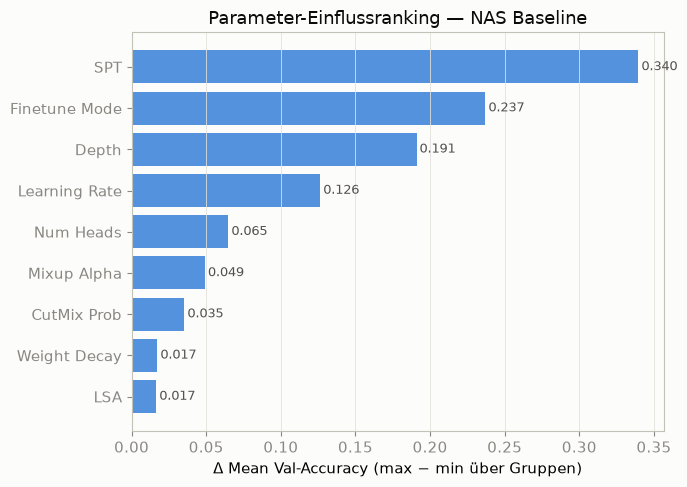

use_spt          0.339612
finetune_mode    0.237089
depth            0.190900
lr               0.126407
num_heads        0.064845
mixup_alpha      0.049139
cutmix_prob      0.035385
weight_decay     0.017276
use_lsa          0.016537


In [20]:
influence = {}
for col in params:
    means = baseline.groupby(col)["val_acc"].mean()
    influence[col] = means.max() - means.min()

inf_df = pd.Series(influence, name="Einfluss (Δ mean val_acc)") \
           .sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.barh(
    [params[k] for k in inf_df.index],
    inf_df.values,
    color=C1, alpha=0.8
)

# Werte direkt auf die Balken
for bar, val in zip(bars, inf_df.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=9, color="#52514e")

ax.set_xlabel("Δ Mean Val-Accuracy (max − min über Gruppen)")
ax.set_title("Parameter-Einflussranking — NAS Baseline")
ax.grid(True, axis="x")
plt.tight_layout()
plt.savefig("../results/plots/parameter_einfluss.png", dpi=150)
plt.show()

print(inf_df.sort_values(ascending=False).to_string())


Differenz zwischen dem besten und schlechtesten Gruppen-Mittelwert für diesen Parameter.

Konkret für use_spt = 0.339:

Architekturen mit use_spt=0 haben im Mittel val_acc X
Architekturen mit use_spt=1 haben im Mittel val_acc X − 0.339
Die Wahl SPT ja/nein verändert die durchschnittliche Val-Accuracy um 33.9 Prozentpunkte
Das ist der stärkste Einflussfaktor — was direkt mit dem SPT-Ablation-Ergebnis zusammenpasst: SPT mit random init zerstört die pretrained Features.

finetune_mode = 0.237: Je nach Finetune-Modus (head / last2 / last4 / full) schwankt die mittlere Val-Accuracy um 23.7 pp. Welcher Modus am besten ist sieht man im Boxplot.

depth = 0.191: Zwischen flachsten (depth=4) und tiefsten (depth=12) Architekturen liegen 19 pp im Mittel.

lr = 0.126: Die Lernrate beeinflusst das Ergebnis mehr als die Kopfanzahl — interessant, weil lr oft als "nur Hyperparameter" gilt.

use_lsa = 0.017: LSA hat quasi keinen messbaren Einfluss — ähnlich wie SPT ist es wahrscheinlich nicht mit dem Fine-Tuning-Paradigma kompatibel, aber der Effekt ist viel schwächer weil LSA keine Layer-Shape verändert

## Pareto-Front-Zusammensetzung

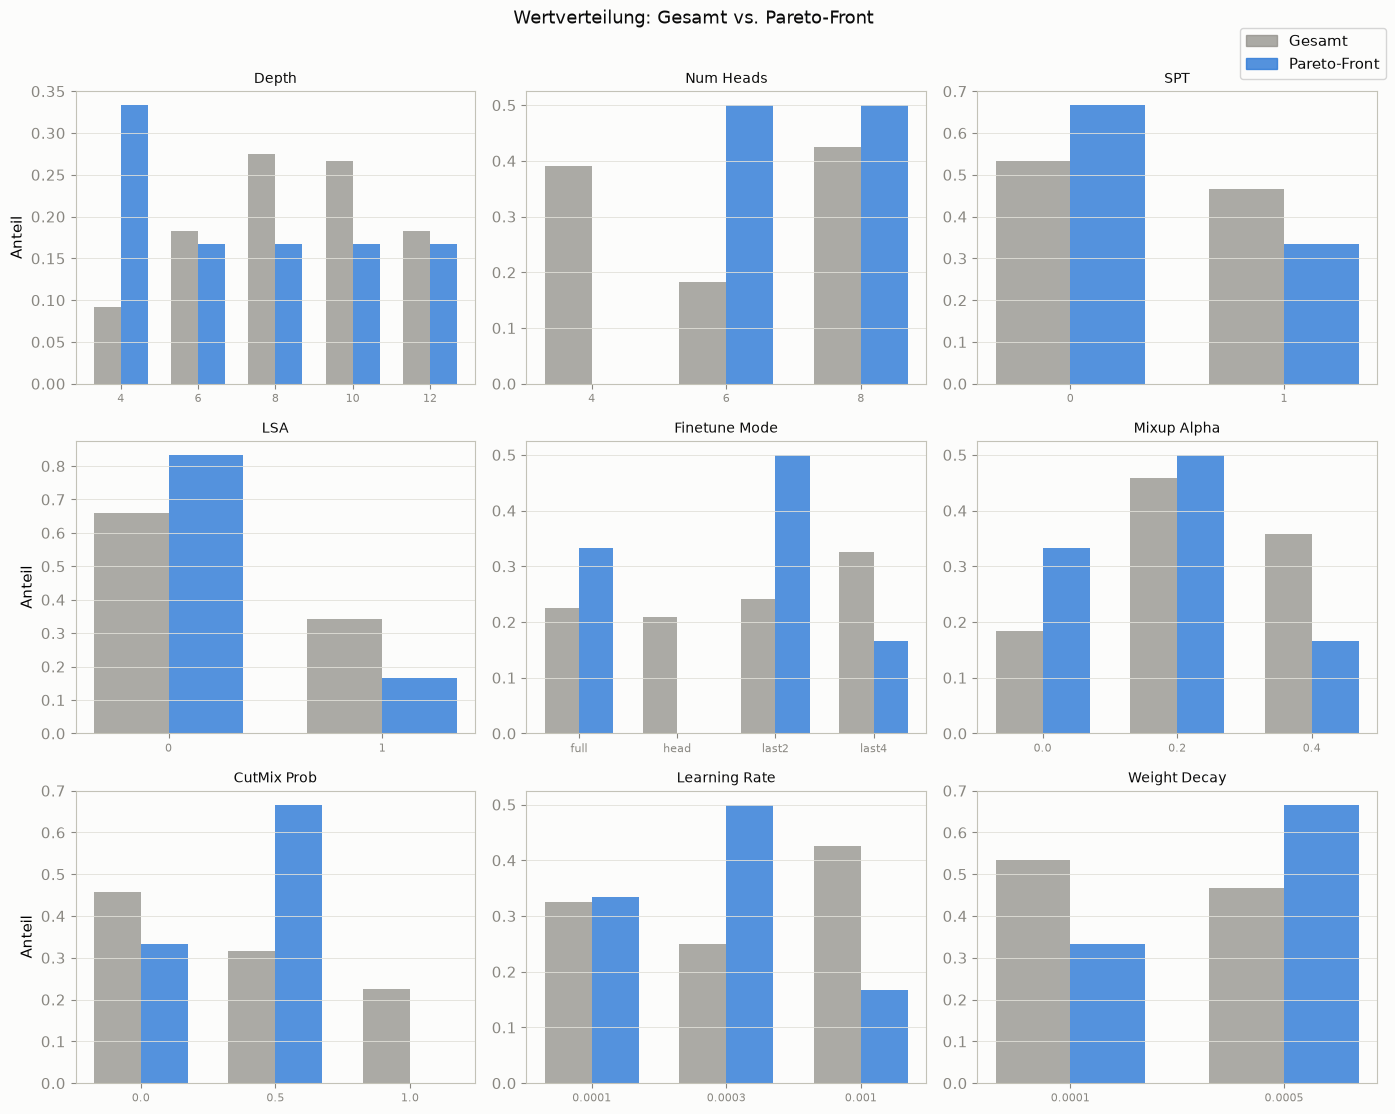

In [21]:
mask = pareto_front(baseline)
pareto_df = baseline[mask]

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()

for ax, (col, label) in zip(axes, params.items()):
    values = sorted(baseline[col].unique())
    
    total_frac  = [len(baseline[baseline[col] == v]) / len(baseline) for v in values]
    pareto_frac = [len(pareto_df[pareto_df[col] == v]) / max(len(pareto_df), 1) for v in values]
    
    x = np.arange(len(values))
    w = 0.35
    ax.bar(x - w/2, total_frac,  w, color=MUTED, alpha=0.7, label="Gesamt")
    ax.bar(x + w/2, pareto_frac, w, color=C1,    alpha=0.8, label="Pareto-Front")
    
    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in values], fontsize=8)
    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Anteil" if ax in axes[::3] else "")
    ax.grid(True, axis="y")

handles = [mpatches.Patch(color=MUTED, alpha=0.7, label="Gesamt"),
           mpatches.Patch(color=C1,    alpha=0.8, label="Pareto-Front")]
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(1.0, 1.0))
plt.suptitle("Wertverteilung: Gesamt vs. Pareto-Front", y=1.01)
plt.tight_layout()
plt.savefig("../results/plots/pareto_komposition.png", dpi=150, bbox_inches="tight")
plt.show()


## Heatmap depth × finetune_mode

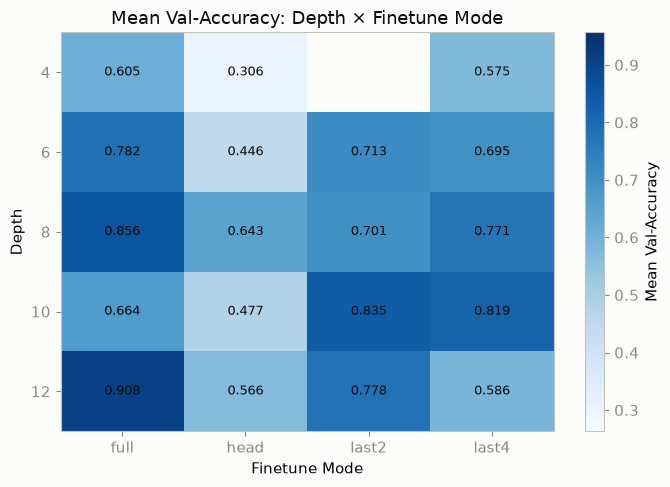

In [22]:
pivot = baseline.pivot_table(
    values="val_acc",
    index="depth",
    columns="finetune_mode",
    aggfunc="mean"
)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto",
               vmin=baseline["val_acc"].min(),
               vmax=baseline["val_acc"].max())

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Finetune Mode")
ax.set_ylabel("Depth")
ax.set_title("Mean Val-Accuracy: Depth × Finetune Mode")

# Werte in Zellen
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                    fontsize=9, color="#0b0b0b")

plt.colorbar(im, ax=ax, label="Mean Val-Accuracy")
plt.tight_layout()
plt.savefig("../results/plots/heatmap_depth_finetune.png", dpi=150)
plt.show()
